# WST IFS modes in `slicersim`

The **Wide-field Spectroscopic Telescope (WST) integral-field spectrograph** (blue and red
channels) is available in `slicersim` (branch `wst`). The instrument description and the
site approximations follow the WST ETC [`pyetc`](https://github.com/RolandBacon/pyetc) (`pyetc/wst.py`,
`pyetc/etc.py`). This notebook presents the implementation, validates it against pyetc
itself, and shows how to use it.

`slicersim` was built for a space slicer IFS (Lazuli): no atmosphere, diffraction-limited
PSF, zodiacal background, HxRG detector read up-the-ramp. WST is a ground-based 12 m
telescope with a seeing-limited PSF, Paranal sky and CCDs. The notebook covers:

1. **Implementation**: new modules, classes and configuration files;
2. **Instrument inputs**: throughput, sky, seeing-induced and optical PSF;
3. **Validation against pyetc**: photon budgets and SNR;
4. **Using the WST modes**: SNR, variance budget, observing conditions, exposure time, host galaxy;
5. **Limitations**.

**Main outcome.** With the same inputs, slicersim reproduces pyetc's source and sky photon
counts to ≲10⁻⁴ (median), and pyetc's *resolved-source* SNR to 5 digits. It also exposes
issues of pyetc's *point source + continuum* path, which over-predicts the SNR (§3, and the
[pyetc issues](https://github.com/RolandBacon/pyetc/issues) reported on GitHub):

- the **sky noise is counted for a single spaxel** instead of the `nspaxels` of the aperture
  (`ETC.snr_from_ps_spec`): SNR 29.2 instead of 22.1 for a 5×5 box in dark time, and ×7 too
  high in bright time with a 9×9 box ([pyetc#3](https://github.com/RolandBacon/pyetc/issues/3));
- the **Moffat PSF is truncated** to a ~2 FWHM box and renormalised (`etc.moffat(kfwhm=2)`),
  which over-estimates the flux in the aperture by 15–25 % ([pyetc#4](https://github.com/RolandBacon/pyetc/issues/4)).

*Requirements*: slicersim (branch `wst`). The pyetc repository is only needed to regenerate
the configuration files (§1.3) and for the cross-check of §3, which also needs pyetc
importable (`mpdaf`, `skycalc_cli`, `spextra`); its data tables are found next to the
installed `pyetc` package. Both are skipped otherwise.

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator

import slicersim
from slicersim import WSTTarget, wst_etc
from slicersim.atmosphere import get_seeing_fwhm
from slicersim.iotools import PACKAGE_PATH
from slicersim.wst import WST_INSTRUMENTS, make_wst_config_files

warnings.filterwarnings("ignore", message="IProgress not found")  # tqdm, via mpdaf
try:  # pyetc WST data tables, installed with the package (pyetc/data/WST)
    import pyetc
    PYETC_DATA = Path(pyetc.__file__).parent / "data" / "WST"
except ImportError:
    PYETC_DATA = None
HAS_PYETC_DATA = PYETC_DATA is not None and PYETC_DATA.is_dir()

MOONS = ("darksky", "greysky", "brightsky")
print("slicersim", slicersim.__version__, "| pyetc data:", "found" if HAS_PYETC_DATA else "not found")

slicersim 1.4.2 | pyetc data: found


## 1. Implementation

### 1.1 What changes from Lazuli to WST

| | pyetc (WST IFS) | slicersim (Lazuli) | WST in slicersim |
|---|---|---|---|
| Collecting area | 100 m² × (1 − 0.18 IFS obscuration) | π(D²−d²)/4 | `telescope.surface = 82` m² |
| Spatial PSF | Moffat β=2.5, FWHM = seeing ⊕ 0.10″ tel+ins | Gaussian ∝ λ (diffraction) ⊕ jitter, or Airy | Moffat, FWHM = **seeing-induced** (`Atmosphere`) ⊕ **optical** (`optical_fwhm`) |
| Seeing | ESO ETC model: seeing at 5000 Å, airmass^0.6, λ^−1/5, outer-scale term for D=12 m | — | `atmosphere.get_seeing_fwhm` |
| Atmospheric transmission | skycalc `trans` (Paranal, per airmass), on the source only | — | `Atmosphere.get_transmission`, on astrophysical sources only |
| Background | skycalc emission (dark/grey/bright, airmass 1.0–2.0) | zodiacal light | `Atmosphere.get_emission`, as the scene background |
| Throughput | `ifs_<chan>_noatm.fits` (TOT, includes QE) | per-element CSV + detector QE | `wst_ifs_<chan>_throughput.csv`, QE = 1 |
| Wavelengths | linear: λ₁ + k·Δλ (0.64 / 0.97 Å) | dispersion law or constant R | linear `wst_ifs_<chan>_dispersion.ecsv` |
| LSF | Gaussian FWHM = 2.5 px (also used by skycalc) | σ = `dispersion_resolution`/2 | σ = FWHM/2.355; sky tables not re-convolved |
| Sampling | 1 voxel (0.25″ spaxel × 1 spectel) = 1 pixel | anamorphosis ×2 | no anamorphosis |
| Detector | CCD: RON 3 e⁻/read, dark 3 e⁻/h, NDIT × DIT | HxRG, MACC up-the-ramp | `CCDDetector`, NDIT ≡ `nramps` (alias `ndit`) |
| Extraction | square box (2n+1)² or adaptive circle | optimal or circular | both, plus pyetc box (`method="box"`) |
| ETC | flux for a given SNR | MACC mode & number of ramps | NDIT for a fixed DIT, or DIT for a fixed NDIT |

SNRs below are **per spectral pixel** (pyetc's convention), unless stated otherwise
(`per_resolution=True` multiplies by √2.5).

### 1.2 New code

| Module | Content |
|---|---|
| `slicersim/atmosphere.py` (new) | `get_seeing_fwhm` (**seeing-induced** FWHM only, ESO ETC model), `moffat_density` (seeing-limited PSF profile), `read_sky_table`, `Atmosphere` (seeing, airmass, moon; tabulated transmission and sky emission) |
| `slicersim/ground_spectrograph.py` (new) | `GroundSlicerSpectrograph(SlicerSpectrograph)`: Moffat PSF whose FWHM combines the seeing-induced FWHM of its `atmosphere` and the **optical** FWHM (`optical_fwhm`, telescope + instrument) in quadrature, see `get_psf_fwhm(which="seeing"/"optical"/"total")` and `get_spatial_psf(incl_atmosphere=, incl_telescope=)`; transmission in `flambda2photon` but not on the sky; LSF FWHM convention; no anamorphosis; `get_box_aperture` |
| `slicersim/detector.py` | `CCDDetector(Detector)`: variance $(f+d)\,\mathrm{DIT} + \mathrm{RON}^2$ per exposure |
| `slicersim/wst.py` (new) | `WSTSimulation` (atmosphere wiring, LSF before transmission, `"box"` extraction, CCD `fetch_snr`), `WSTTarget`, `wst_etc`, `make_wst_config_files` (maintenance) |
| `slicersim/thermal.py` | no divide-by-zero warning for T = 0 K ("no thermal emission") |
| `slicersim/config/` | `wst_ifs_{blue,red}.toml`, `_throughput.csv`, `_dispersion.ecsv`, `_sky.ecsv` (transmission and emission for airmass 1.0–2.0 × 3 moon conditions) |
| `tests/test_wst.py` (new) | including the pyetc regression value |

`seeing`, `airmass`, `moon`, `optical_fwhm`, `moffat_beta`, `moffat_truncation`, `dit` and
`ndit` are regular mutable parameters: `target.change_properties(seeing=0.6, moon="greysky")`.

In [2]:
print((PACKAGE_PATH / "config" / WST_INSTRUMENTS["blue"]).read_text())

# WST IFS blue channel
# Generated by slicersim.wst.make_wst_config_files from pyetc (data files):
# pyetc/wst.py (Inspired from BlueMUSE throughput, version 0.1 10/02/2023) and pyetc/data/WST tables.

# ============= #
#  Atmosphere   #
# ============= #
[atmosphere]
site = "Paranal"
sky_table = "wst_ifs_blue_sky.ecsv"    # ESO SkyCalc (via pyetc): transmission & emission
seeing = 0.8                    # Seeing FWHM [arcsec] at 5000 A and zenith (seeing-induced PSF)
airmass = 1.0                   # Airmass (tabulated: 1.0, 1.2, 1.5, 2.0)
moon = "darksky"                # Sky condition: darksky, greysky, brightsky

# ============= #
#  Telescope    #
# ============= #
[telescope]
diameter_ext = 12.0             # Primary mirror external diameter [m] (seeing model)
diameter_int = 0.0
surface = 82.0                 # Collecting area [m2] = 100.0 m2 x (1 - 0.18 IFS obscuration)
temperature = 0                 # No thermal emission in the optical
emissivity = 0

# ============= #
# Spect

### 1.3 Configuration files from pyetc

The configuration files were generated from the pyetc `data/WST` tables with
`make_wst_config_files` (throughput resampled on the instrument grid as pyetc does, sky
emission converted from ph/s/m²/µm/arcsec² to erg/s/cm²/Å/arcsec², values rounded to 5–6
significant digits). Regenerating them in a temporary directory checks that the packaged
files are up to date:

In [3]:
import tempfile
from astropy.table import Table

if HAS_PYETC_DATA:
    with tempfile.TemporaryDirectory() as tmp:
        make_wst_config_files(PYETC_DATA, outdir=tmp)
        for name in sorted(p.name for p in Path(tmp).iterdir() if p.suffix in (".csv", ".ecsv")):
            new, ref = Path(tmp) / name, PACKAGE_PATH / "config" / name
            if name.endswith(".csv"):
                same = new.read_text() == ref.read_text()
            else:
                tn, tr = Table.read(new, format="ascii.ecsv"), Table.read(ref, format="ascii.ecsv")
                same = tn.colnames == tr.colnames and all(np.array_equal(tn[c], tr[c]) for c in tn.colnames)
            print(f"{name:35s} {'identical' if same else 'DIFFERENT'}")
else:
    print("pyetc data not found: check skipped")

wst_ifs_blue_dispersion.ecsv        identical
wst_ifs_blue_sky.ecsv               identical
wst_ifs_blue_throughput.csv         identical
wst_ifs_red_dispersion.ecsv         identical
wst_ifs_red_sky.ecsv                identical
wst_ifs_red_throughput.csv          identical


## 2. Instrument inputs

A flat $F_\lambda$ point source, observed in each channel with the default conditions
(dark sky, airmass 1, seeing 0.8″).

In [4]:
LBDA = np.linspace(3000, 11000, 8001)  # [Å] input spectra, wider than both channels

def flat(flux=1e-17):
    return np.full_like(LBDA, flux)

def ab_flux(mag):
    # F_lambda [erg/s/cm²/Å] of a flat-F_nu source of AB magnitude mag
    return 10 ** (-0.4 * (mag + 48.6)) * 2.99792458e18 / LBDA ** 2

targets = {ch: WSTTarget(LBDA, flat(), channel=ch) for ch in WST_INSTRUMENTS}
for ch, t in targets.items():
    sim = t.simulation
    sp = sim.spectrograph
    l, R = sim.get_resolving_power()
    print(f"{ch:4s}: {sp.nlbda} px, {sp.lbda[0]:.2f}-{sp.lbda[-1]:.2f} Å, "
          f"Δλ={np.diff(sp.lbda).mean():.4f} Å, R={R[0]:.0f}-{R[-1]:.0f}, "
          f"spaxels {tuple(int(n) for n in sp.spx_shape)} × {sp.spx_spatial_scale}″, "
          f"surface {sim.telescope.surface} m² | {sim.atmosphere}")

blue: 3751 px, 3700.00-6100.00 Å, Δλ=0.6400 Å, R=2312-3813, spaxels (25, 25) × 0.25″, surface 82.0 m² | Atmosphere (Paranal): seeing 0.8", airmass 1.0, darksky
red : 3712 px, 6000.00-9599.67 Å, Δλ=0.9700 Å, R=2474-3959, spaxels (25, 25) × 0.25″, surface 82.0 m² | Atmosphere (Paranal): seeing 0.8", airmass 1.0, darksky


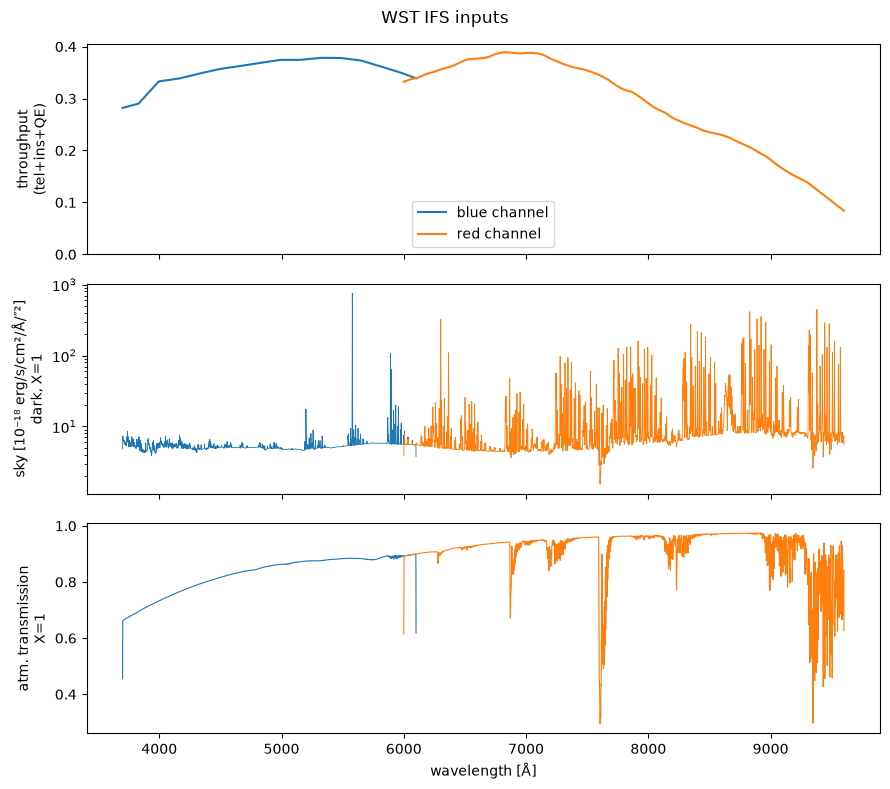

In [5]:
fig, axs = plt.subplots(3, 1, figsize=(9, 8), sharex=True)
for i, (ch, t) in enumerate(targets.items()):
    sim = t.simulation
    sp = sim.spectrograph
    l = sp.lbda
    axs[0].plot(l, sp.get_throughput(), color=f"C{i}", label=f"{ch} channel")
    axs[1].plot(l, sim.atmosphere.get_emission(l) * 1e18, color=f"C{i}", lw=0.6, label=f"{ch} channel")
    axs[2].plot(l, sp.get_atmospheric_transmission(), color=f"C{i}", lw=0.8, label=f"{ch} channel")
axs[0].set(ylabel="throughput\n(tel+ins+QE)", ylim=(0, None))
axs[1].set(ylabel="sky [10⁻¹⁸ erg/s/cm²/Å/″²]\ndark, X=1", yscale="log")
axs[2].set(ylabel="atm. transmission\nX=1", xlabel="wavelength [Å]")
axs[0].legend(loc="lower center")
fig.suptitle("WST IFS inputs")
fig.tight_layout()

The first and last pixels of the skycalc tables are affected by their LSF convolution
(drop of the transmission, sky spikes), in pyetc as here: avoid the channel edges.

**Seeing-induced vs optical PSF.** The atmosphere provides the seeing-induced FWHM, the
spectrograph the achromatic optical FWHM (`optical_fwhm` = 0.10″, telescope + instrument);
the PSF is a Moffat of their quadratic sum (pyetc approximation). Each component can be
isolated:

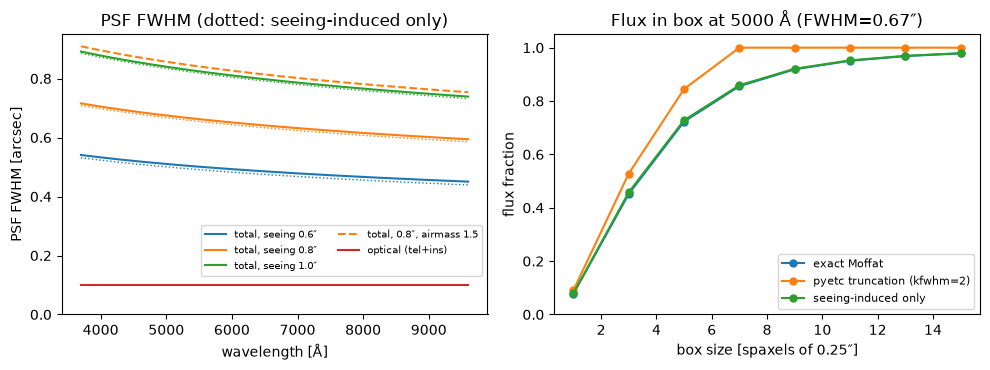

In [6]:
sim = targets["blue"].simulation
sp = sim.spectrograph
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.8))
lb = np.linspace(3700, 9600, 200)
for i, seeing in enumerate([0.6, 0.8, 1.0]):
    sim.update(seeing=seeing)
    ax1.plot(lb, sp.get_psf_fwhm(lb, which="total"), color=f"C{i}", label=f"total, seeing {seeing}″")
    ax1.plot(lb, sp.get_psf_fwhm(lb, which="seeing"), color=f"C{i}", ls=":", lw=1)
sim.update(seeing=0.8, airmass=1.5)
ax1.plot(lb, sp.get_psf_fwhm(lb), color="C1", ls="--", label="total, 0.8″, airmass 1.5")
sim.update(airmass=1.0)
ax1.plot(lb, sp.get_psf_fwhm(lb, which="optical"), color="C3", label="optical (tel+ins)")
ax1.set(xlabel="wavelength [Å]", ylabel="PSF FWHM [arcsec]", ylim=(0, None),
        title="PSF FWHM (dotted: seeing-induced only)")
ax1.legend(fontsize=7.5, loc="lower right", bbox_to_anchor=(1, 0.12), ncols=2)

# fraction of the point-source flux in a (2n+1)² box at 5000 Å
k = np.argmin(abs(sp.lbda - 5000))
hsizes = np.arange(0, 8)
for i, (trunc, label, kw) in enumerate([(0, "exact Moffat", {}), (2, "pyetc truncation (kfwhm=2)", {}),
                                       (0, "seeing-induced only", dict(incl_telescope=False))]):
    sim.update(moffat_truncation=trunc)
    psf = sp.get_spatial_psf(**kw)[k]
    ax2.plot(2 * hsizes + 1, [psf[sp.get_box_aperture(hsize=n)].sum() for n in hsizes],
             "o-", ms=5, color=f"C{i}", label=label)
sim.update(moffat_truncation=0)
ax2.set(xlabel="box size [spaxels of 0.25″]", ylabel="flux fraction", ylim=(0, 1.05),
        title=f"Flux in box at 5000 Å (FWHM={sp.get_psf_fwhm([5000.])[0]:.2f}″)")
ax2.xaxis.set_major_locator(MultipleLocator(2))
ax2.legend(loc="lower right", fontsize=8)
fig.tight_layout()

With β = 2.5 the Moffat wings are heavy: a 5×5 box (1.25″) only contains ~72 % of the flux
at 0.8″ seeing, while pyetc's truncated PSF puts ~85 % in it (and 100 % in a ≥ 7×7 box), see [pyetc#4](https://github.com/RolandBacon/pyetc/issues/4).
The 0.10″ optical contribution is small compared to the seeing.

## 3. Validation against pyetc

Same observation in both codes: flat $F_\lambda = 10^{-17}$ erg/s/cm²/Å point source,
NDIT × DIT = 2 × 1800 s, pyetc `square_fixed` aperture. slicersim is run (i) with pyetc's PSF
truncation and the box extraction, to compare like with like, then (ii) with the exact Moffat,
and (iii) with its optimal extraction.

pyetc is imported if available; otherwise this section is skipped.

In [7]:
import logging
try:
    from pyetc.wst import WST
    wst = WST(log=logging.WARNING)
    HAS_PYETC = True
except ImportError as e:
    HAS_PYETC = False
    print("pyetc not importable, validation skipped:", e)

NDIT, DIT = 2, 1800.

def run_pyetc(channel, nsp, seeing, moon, airmass, flux=1e-17, ima_type="ps", ima=None):
    ins = wst.ifs[channel]
    spec = wst.get_spec(ins, dict(type="flatcont", wave=[ins["lbda1"] + 1, ins["lbda2"] - 1]))
    wst.set_obs(dict(moon=moon, airmass=airmass, seeing=seeing, ndit=NDIT, dit=DIT,
                     spec_type="cont", ima_type=ima_type,
                     ima_aperture_type="square_fixed", ima_aperture_hsize_spaxels=nsp))
    res = wst.snr_from_source(ins, flux, ima, spec)["spec"]
    out = {k: np.asarray(res[k].data, dtype=float) for k in ("snr", "nph_source", "nph_sky")}
    out["lbda"] = res["snr"].wave.coord()
    out["nspaxels"] = res["nb_spaxels"]
    return out

def run_slicersim(channel, nsp, seeing, moon, airmass, flux=1e-17):
    sim = WSTTarget(LBDA, flat(flux), channel=channel, seeing=seeing, moon=moon, airmass=airmass).simulation
    sim.update(dit=DIT, ndit=NDIT)
    out = {}
    for trunc in (2, 0):
        sim.update(moffat_truncation=trunc)
        l, s, v = sim.get_spectrum(method="box", box_hsize=nsp)
        out[f"box{trunc}"] = (s, v)
    l, s, v = sim.get_spectrum(method="optimal")
    out["optimal"] = (s, v)
    # sky photons in a single spaxel (pyetc nph_sky)
    out["sky1"] = sim.get_projected_scene(switch_off=["pointsource", "host", "thermal"])[:, 0, 0] * DIT * NDIT
    out["lbda"] = l
    out["ron2_dark"] = sim.detector.ron ** 2 * NDIT + sim.detector.dark * DIT * NDIT  # per spaxel [e-²]
    return out

def match(l_ref, l):
    # indices of l_ref matching l (same grid up to round-off)
    idx = np.clip(np.searchsorted(l_ref, l - 1e-3), 0, len(l_ref) - 1)
    assert np.all(abs(l_ref[idx] - l) < 1e-3)
    return idx

In [8]:
CONFIGS = [  # channel, box half-size, seeing, moon, airmass
    ("blue", 2, 0.8, "darksky", 1.0),
    ("red",  2, 1.0, "darksky", 1.0),   # red @0.8": pyetc crashes (pyetc#5, https://github.com/RolandBacon/pyetc/issues/5)
    ("red",  3, 1.0, "greysky", 1.2),
    ("blue", 4, 1.0, "brightsky", 1.5),
]
snr_of = lambda sv: sv[0] / np.sqrt(sv[1])
rows, RESULTS = [], {}
if HAS_PYETC:
    for conf in CONFIGS:
        p, s = run_pyetc(*conf), run_slicersim(*conf)
        RESULTS[conf] = p, s
        idx = match(s["lbda"], p["lbda"])
        n = p["nspaxels"]
        src = s["box2"][0][idx]
        sky1 = s["sky1"][idx]
        med = lambda a: float(np.nanmedian(a))
        rows.append({
            "channel": conf[0], "box": f"{2*conf[1]+1}²", "seeing": conf[2], "sky": conf[3], "airmass": conf[4],
            "source / pyetc": med(src / p["nph_source"]),
            "sky(1 spx) / pyetc": med(sky1 / p["nph_sky"]),
            "SNR pyetc": med(p["snr"]),
            "pyetc formula, 1-spaxel sky": med(src / np.sqrt(src + sky1 + n * s["ron2_dark"])),
            "slicersim box (pyetc PSF)": med(snr_of(s["box2"])[idx]),
            "slicersim box (exact Moffat)": med(snr_of(s["box0"])[idx]),
            "slicersim optimal": med(snr_of(s["optimal"])[idx]),
        })
    VALID = pd.DataFrame(rows)
    display(VALID.round(4))

,channel,box,seeing,sky,airmass,source / pyetc,sky(1 spx) / pyetc,SNR pyetc,"pyetc formula, 1-spaxel sky",slicersim box (pyetc PSF),slicersim box (exact Moffat),slicersim optimal
0,blue,5²,0.8,darksky,1.0,1.0,1.0,29.2151,29.2151,22.0644,19.4379,21.4664
1,red,5²,1.0,darksky,1.0,1.0,1.0,42.6894,42.6894,29.1360,24.3745,26.9051
2,red,7²,1.0,greysky,1.2,1.0,1.0,43.4271,43.4271,19.6257,16.1121,19.1773
3,blue,9²,1.0,brightsky,1.5,1.0,1.0,16.4784,16.4784,2.4383,1.8981,2.4201


- **Photon budgets agree**: with the same PSF approximation, the source photons in the box and
  the sky photons per spaxel are identical (ratios = 1.0000 in the median). The wavelength
  grids are identical.
- **pyetc's point-source SNR is reproduced exactly** by its own formula
  `S/√(S + sky₁ + n_spx·(RON²·NDIT + dark))`, where `sky₁` is the sky of a **single** spaxel
  (`ETC.snr_from_ps_spec`). Summing the sky over the aperture (slicersim, "box") lowers the SNR
  by 25 % in dark time and by a factor ≈ √n_spx when sky-dominated (×7 for a 9×9 box in bright time).
- The **exact Moffat** removes another 10–20 % (wings outside the box), and slicersim's
  **optimal extraction** recovers part of it.

The sky-noise issue ([pyetc#3](https://github.com/RolandBacon/pyetc/issues/3)) is confirmed by pyetc itself: its *resolved*-source path (`snr_from_cube`),
which sums the variance cube over the spaxels, gives the slicersim value when fed with the PSF
image as a "resolved" source:

In [9]:
if HAS_PYETC:
    ins = wst.ifs["blue"]
    wst.set_obs(dict(seeing=0.8, airmass=1.0))
    psf_5000 = wst.get_image_psf(ins, 5000.)  # pyetc (truncated) Moffat PSF at 5000 Å
    ps = run_pyetc("blue", 2, 0.8, "darksky", 1.0)
    rs = run_pyetc("blue", 2, 0.8, "darksky", 1.0, ima_type="resolved", ima=psf_5000)
    p, s = RESULTS[CONFIGS[0]]
    kp = np.argmin(abs(ps["lbda"] - 5000)); ks = np.argmin(abs(s["lbda"] - 5000))
    print("SNR at 5000 Å, blue, 5x5 box, 0.8\", dark, 2x1800 s")
    print(f"  pyetc point source (snr_from_ps_spec): {ps['snr'][kp]:.4f}")
    print(f"  pyetc resolved     (snr_from_cube):    {rs['snr'][kp]:.4f}")
    print(f"  slicersim box, pyetc PSF:              {snr_of(s['box2'])[ks]:.4f}")

SNR at 5000 Å, blue, 5x5 box, 0.8", dark, 2x1800 s
  pyetc point source (snr_from_ps_spec): 29.9687
  pyetc resolved     (snr_from_cube):    23.0663
  slicersim box, pyetc PSF:              23.0662


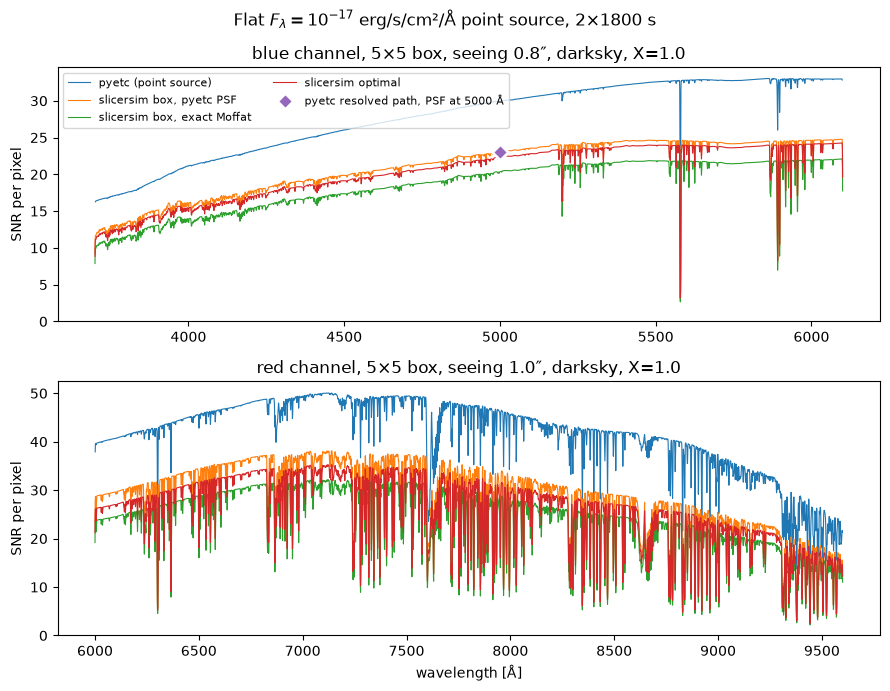

In [10]:
if HAS_PYETC:
    fig, axs = plt.subplots(2, 1, figsize=(9, 7))
    for ax, conf in zip(axs, CONFIGS[:2]):
        p, s = RESULTS[conf]
        l = s["lbda"]
        ax.plot(p["lbda"], p["snr"], color="C0", lw=0.8, label="pyetc (point source)")
        ax.plot(l, snr_of(s["box2"]), color="C1", lw=0.8, label="slicersim box, pyetc PSF")
        ax.plot(l, snr_of(s["box0"]), color="C2", lw=0.8, label="slicersim box, exact Moffat")
        ax.plot(l, snr_of(s["optimal"]), color="C3", lw=0.8, label="slicersim optimal")
        if conf == CONFIGS[0]:
            ax.plot([5000], [rs["snr"][kp]], "D", ms=8, color="C4", mec="white", mew=2,
                    label="pyetc resolved path, PSF at 5000 Å")
        ax.set(ylabel="SNR per pixel", ylim=(0, None),
               title=f"{conf[0]} channel, {2*conf[1]+1}×{2*conf[1]+1} box, seeing {conf[2]}″, {conf[3]}, X={conf[4]}")
    axs[0].legend(ncols=2, fontsize=8, loc="upper left")
    axs[1].set_xlabel("wavelength [Å]")
    fig.suptitle(r"Flat $F_\lambda=10^{-17}$ erg/s/cm²/Å point source, 2×1800 s")
    fig.tight_layout()

## 4. Using the WST modes

Defaults: exact Moffat PSF, optimal extraction.

### 4.1 SNR and variance budget

blue: median SNR/pixel 16.1, per resolution element 23.9


red: median SNR/pixel 10.5, per resolution element 14.5


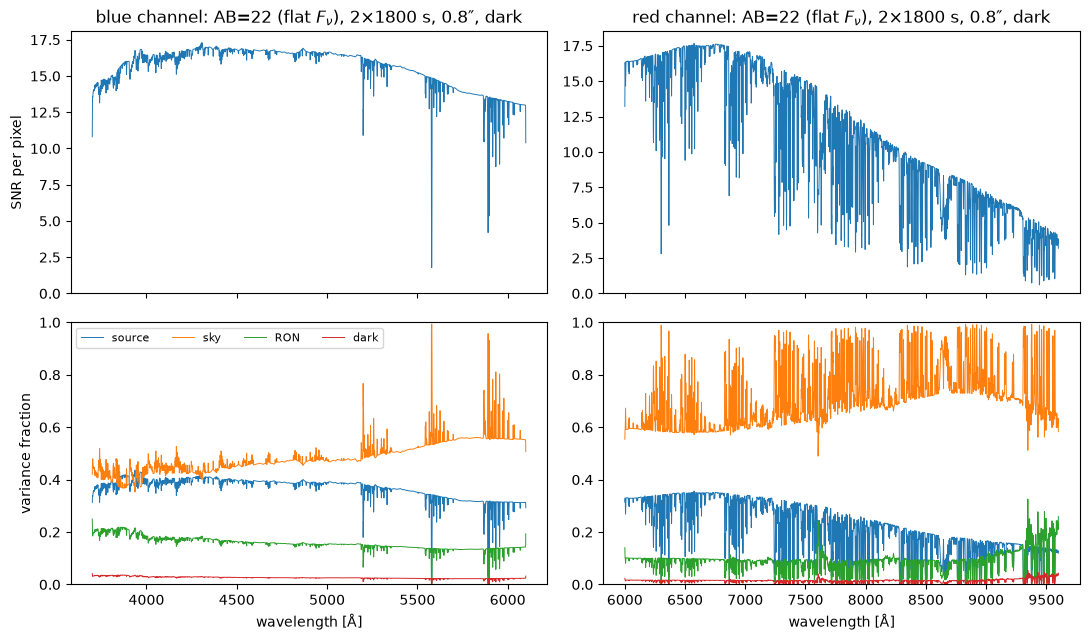

In [11]:
fig, axs = plt.subplots(2, 2, figsize=(11, 6.5), sharex="col")
for j, ch in enumerate(WST_INSTRUMENTS):
    t = WSTTarget(LBDA, ab_flux(22), channel=ch, seeing=0.8, moon="darksky", airmass=1.0)
    t.change_properties(dit=1800., ndit=2)
    vc = t.simulation.get_variance_contribution()
    l = vc["lbda"]
    axs[0, j].plot(l, vc["flux"] / np.sqrt(vc["variance"]), color="C0", lw=0.7)
    axs[0, j].set(title=f"{ch} channel: AB=22 (flat $F_\\nu$), 2×1800 s, 0.8″, dark",
                  ylabel="SNR per pixel" if j == 0 else None, ylim=(0, None))
    for i, src in enumerate(["pointsource", "background", "ron", "dark"]):
        axs[1, j].plot(l, vc[src] / vc["variance"], color=f"C{i}", lw=0.7,
                       label={"pointsource": "source", "background": "sky", "ron": "RON"}.get(src, src))
    axs[1, j].set(xlabel="wavelength [Å]", ylabel="variance fraction" if j == 0 else None, ylim=(0, 1))
    print(f"{ch}: median SNR/pixel {np.nanmedian(vc['flux'] / np.sqrt(vc['variance'])):.1f}, "
          f"per resolution element {t.get_band_snr([l.iloc[0] + 50, l.iloc[-1] - 50], per_resolution=True):.1f}")
axs[1, 0].legend(ncols=4, fontsize=8, loc="upper left")
fig.tight_layout()

### 4.2 Observing conditions

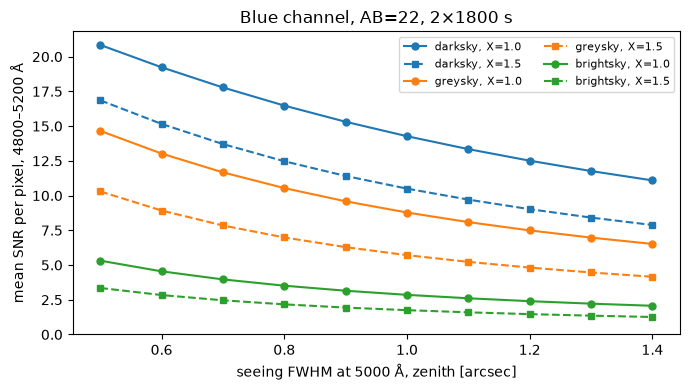

In [12]:
t = WSTTarget(LBDA, ab_flux(22), channel="blue")
t.change_properties(dit=1800., ndit=2)
band = [4800, 5200]
seeings = np.linspace(0.5, 1.4, 10)
fig, ax = plt.subplots(figsize=(7, 4))
for moon in MOONS:
    for airmass in (1.0, 1.5):
        snr = []
        for seeing in seeings:
            t.change_properties(seeing=seeing, moon=moon, airmass=airmass)
            snr.append(t.get_band_snr(band, per_resolution=False))
        ax.plot(seeings, snr, "o-" if airmass == 1.0 else "s--", ms=5, color=f"C{MOONS.index(moon)}",
                label=f"{moon}, X={airmass}")
ax.set(xlabel="seeing FWHM at 5000 Å, zenith [arcsec]", ylabel="mean SNR per pixel, 4800–5200 Å",
       title="Blue channel, AB=22, 2×1800 s", ylim=(0, None))
ax.legend(ncols=2, fontsize=8)
fig.tight_layout()

### 4.3 Exposure-time calculator

`wst_etc`, and `fetch_snr` / `setup_to_snr` of the targets, return the smallest NDIT reaching
the SNR for a fixed DIT, or the DIT for a fixed NDIT (warning if saturation, e.g. of bright red
sky lines with very long DITs, prevents it). Here: mean SNR = 10 per pixel in a 400 Å window
centred in each channel, dark sky, 0.8″, airmass 1, DIT = 1800 s.

channel,NDIT (blue),NDIT (red)
mag,,
19.0,1,1
19.5,1,1
20.0,1,1
20.5,1,1
21.0,1,1
21.5,1,1
22.0,1,2
22.5,2,4
23.0,4,10


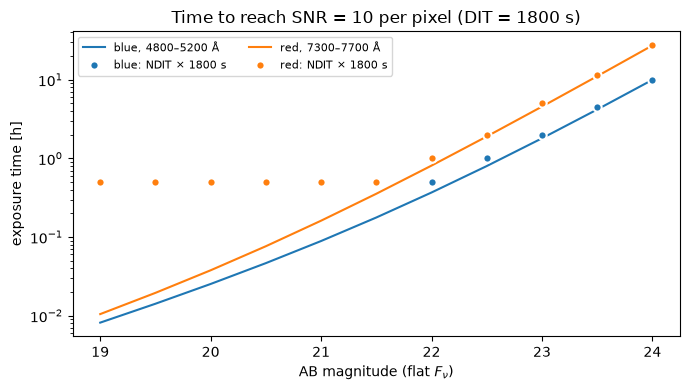

In [13]:
WINDOWS = {"blue": [4800, 5200], "red": [7300, 7700]}
DIT = 1800.
mags = np.arange(19, 24.1, 0.5)
rows = []
for ch in WST_INSTRUMENTS:
    for mag in mags:
        exptime, t = wst_etc(LBDA, ab_flux(mag), 10, channel=ch, lbda_range=WINDOWS[ch], dit=DIT)
        sim = t.simulation
        sim.update(ndit=1)
        snr1 = sim.get_band_snr(WINDOWS[ch], frame="obs")
        rows.append(dict(channel=ch, mag=mag, ndit=int(exptime / DIT), total=exptime,
                         ideal=DIT * (10 / snr1) ** 2))  # NDIT not rounded
ETC = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(7, 4))
for i, ch in enumerate(WST_INSTRUMENTS):
    d = ETC[ETC.channel == ch]
    ax.plot(d.mag, d.ideal / 3600, "-", color=f"C{i}", label=f"{ch}, {WINDOWS[ch][0]}–{WINDOWS[ch][1]} Å")
    ax.plot(d.mag, d.total / 3600, "o", ms=6, color=f"C{i}", mec="white", mew=1.5, label=f"{ch}: NDIT × {DIT:.0f} s")
ax.set(yscale="log", xlabel="AB magnitude (flat $F_\\nu$)", ylabel="exposure time [h]",
       title=f"Time to reach SNR = 10 per pixel (DIT = {DIT:.0f} s)")
ax.legend(ncols=2, fontsize=8)
fig.tight_layout()
display(ETC.pivot(index="mag", columns="channel", values="ndit").rename(columns=lambda c: f"NDIT ({c})"))

In [14]:
# DIT for a fixed NDIT (continuous solution)
exptime, t = wst_etc(LBDA, ab_flux(22), 10, channel="blue", lbda_range=WINDOWS["blue"], ndit=4)
print("fixed NDIT:", t.get_readout_config(), f"total {exptime:.0f} s")

# the generic target API works unchanged: SNR per resolution element (2.5 px) here
t = WSTTarget(LBDA, ab_flux(22.5), channel="red", seeing=0.7)
config, snr = t.setup_to_snr(20, per_resolution=True, lbda_range=WINDOWS["red"], frame="obs", dit=1200.)
print(config, f"SNR/resolution element = {snr:.1f}", t.get_readout_config(), f"total {t.get_exposure_time():.0f} s")

fixed NDIT: {'dit': 471.4669919908864, 'ndit': 4} total 1886 s
{'dit': 1200.0, 'nramps': 8} SNR/resolution element = 20.5 {'dit': 1200.0, 'ndit': 8} total 9600 s


### 4.4 Point source in a host galaxy

Host galaxies (Sérsic or NGC models of slicersim) are convolved with the seeing-limited PSF
like any other structured background.

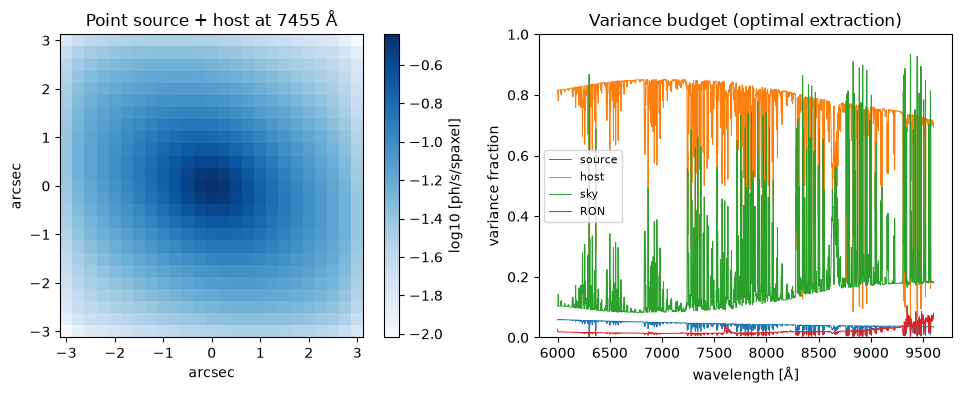

In [15]:
t = WSTTarget(LBDA, ab_flux(22), channel="red", host="sersic:bb-5000", redshift=0.05)
t.change_properties(dit=1800., ndit=2)
sim = t.simulation
cube = sim.get_projected_scene(switch_off=["background"])
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))
im = ax1.imshow(np.log10(cube[1500]), origin="lower", cmap="Blues",
                extent=np.array(sim.spectrograph.spaxel_extent) * sim.spectrograph.spx_spatial_scale)
fig.colorbar(im, ax=ax1, label="log10 [ph/s/spaxel]")
ax1.set(title=f"Point source + host at {sim.spectrograph.lbda[1500]:.0f} Å", xlabel="arcsec", ylabel="arcsec")
ax1.grid(False)
vc = sim.get_variance_contribution()
for i, src in enumerate(["pointsource", "host", "background", "ron"]):
    ax2.plot(vc.lbda, vc[src] / vc.variance, lw=0.7, color=f"C{i}",
             label={"pointsource": "source", "background": "sky", "ron": "RON"}.get(src, src))
ax2.set(xlabel="wavelength [Å]", ylabel="variance fraction", ylim=(0, 1), title="Variance budget (optimal extraction)")
ax2.legend(fontsize=8)
fig.tight_layout()

## 5. Limitations

Same approximations as pyetc unless stated:

- sky tables only for airmass 1.0, 1.2, 1.5, 2.0 and three moon conditions (Paranal,
  pwv 3.5 mm); others can be produced with `pyetc.etc.update_skytables` (skycalc) and
  `make_wst_config_files`;
- the PSF is a single Moffat whose FWHM is the quadratic sum of the seeing-induced and
  optical FWHMs (no separate convolution of the two components); achromatic `optical_fwhm`;
- seeing model of the ESO ETC, with the VLT outer-scale parameters and D = 12 m;
- no sky-subtraction noise, no differential atmospheric refraction;
- saturation is tested at 65535 e⁻ (pyetc does not test it);
- 1 pixel per voxel (no anamorphosis), as pyetc; slicersim's Lazuli convention is 2;
- the simulated sub-field is 25×25 spaxels (6.25″), enough for point sources; the full IFS
  field is not simulated;
- the WST MOS modes (LR/HR, fibre-fed) are out of scope: they are not slicer IFS.